# Uber NYC pickups (Kaggle): clustering

15,000 of the 558,019 Uber pickups in New York City in April 2014 (FiveThirtyEight, via Kaggle), projected to km. No labels; the maps show where each method puts its hotspots (report dataset D3).

Every method is tuned by the shared, label-free rule (`sc4020.tuning`); labels are used only for the
external scores. Sections: dataset loading, one section per method, metrics, visualization. Tables go to
`results/datasets/uber_pickups_results.csv` and `uber_pickups_tuning.csv`, figures to `results/datasets/figures/`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sc4020 import run, tuning
from sc4020.datasets import load_dataset

warnings.filterwarnings("ignore")
np.random.seed(run.SEED)

DATASET_NAME = "uber_pickups"
TOPIC = "datasets"
MAX_CLUSTERS = None  # optional cap on the number of DBSCAN and HDBSCAN clusters

## 1. Dataset loading

In [2]:
ds = load_dataset(DATASET_NAME)
k_range = run.K_RANGES.get(DATASET_NAME, tuning.K_RANGE)
print(ds.DESCR)
print(f"{len(ds.data):,} points, {ds.data.shape[1]} features, classes: {ds.n_true_clusters}")
pd.DataFrame(ds.data, columns=ds.feature_names).describe().round(2)

FiveThirtyEight Uber pickups, April 2014: 15,000 of 558,019 pickups inside NYC (seed 42), projected to km. No labels.
15,000 points, 2 features, classes: None


,x_km,y_km
count,15000.00,15000.00
mean,-6232.53,4530.06
std,3.41,3.70
min,-6244.49,4511.77
25%,-6234.33,4528.19
50%,-6233.27,4530.38
75%,-6232.07,4532.34
max,-6209.26,4549.92


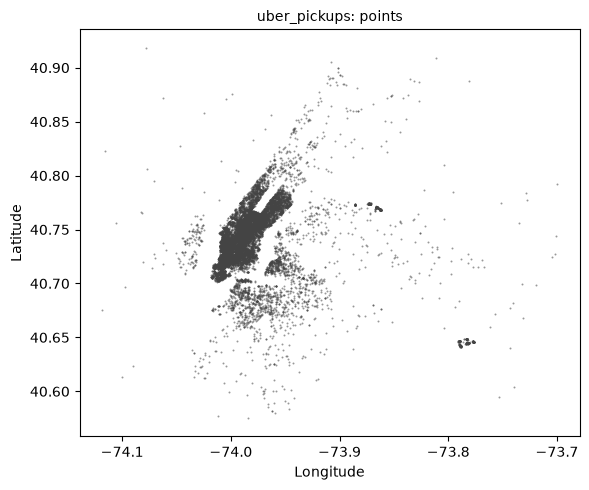

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/uber_pickups_data.png')

In [3]:
from sc4020.generate_figures import plot_coords, scatter_labels, show_and_save

x, y, x_label, y_label = plot_coords(ds)
fig, ax = plt.subplots(figsize=(6, 5))
scatter_labels(
    ax,
    np.column_stack([x, y]),
    ds.target,
    title=f"{DATASET_NAME}: {'classes' if ds.target is not None else 'points'}",
    class_names=ds.get("target_names"),
    size=2 if len(ds.data) > 5000 else 12,
)
ax.set_xlabel(x_label)
ax.set_ylabel(y_label)
fig.tight_layout()
show_and_save(fig, TOPIC, f"{DATASET_NAME}_data")

## 2. Clustering with K-Means

The number of clusters k comes from the fake-data check: for each k, the silhouette on the real data
minus the mean silhouette on copies with every column shuffled, among the k whose seeds agree. On
labelled data K-Means uses the true number of classes, and the label-free choice is shown next to it.
Plain K-Means starts from random centres; K-Means++ (next section) uses the same k.

In [4]:
selections, results = {}, {}
selections["K-Means"] = run.select_method(ds, "K-Means", k_range=k_range)
kmeans_tried = pd.DataFrame(selections["K-Means"].tried)
label_free_k = selections["K-Means"].label_free["n_clusters"]
print(f"k used: {selections['K-Means'].params['n_clusters']}, label-free choice: {label_free_k}")
kmeans_tried.round(3)

k used: 5, label-free choice: 5


,n_clusters,inertia,silhouette,null_silhouette,null_gap,davies_bouldin,smallest_cluster,largest_cluster,mean_seed_ari,min_seed_ari
0,2,249144.811,0.746,0.649,0.097,0.481,458,14542,0.990,0.979
1,3,145439.794,0.448,0.424,0.024,0.676,397,7949,1.000,1.000
2,4,107292.582,0.449,0.401,0.047,0.688,376,7510,0.998,0.995
3,5,76593.079,0.481,0.369,0.112,0.699,356,6673,0.998,0.996
4,6,63532.525,0.441,0.385,0.056,0.676,343,5801,0.924,0.651
5,7,53668.166,0.396,0.373,0.023,0.700,281,4498,0.964,0.903
6,8,45644.994,0.451,0.343,0.108,0.684,168,5410,0.774,0.517
7,9,38758.490,0.413,0.345,0.068,0.728,163,4010,0.992,0.977
8,10,34710.803,0.418,0.347,0.070,0.732,131,3992,0.989,0.970


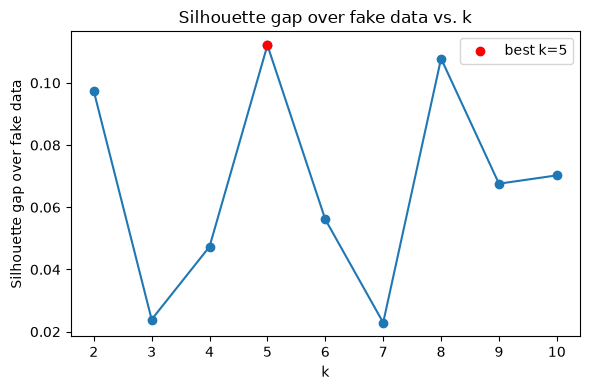

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/uber_pickups_kmeans_k_selection.png')

In [5]:
from sc4020.generate_figures import plot_k_selection, show_and_save

fig = plot_k_selection(
    kmeans_tried["n_clusters"].tolist(),
    kmeans_tried["null_gap"].tolist(),
    best_k=label_free_k,
    ylabel="Silhouette gap over fake data",
)
show_and_save(fig, TOPIC, f"{DATASET_NAME}_kmeans_k_selection")

In [6]:
selections["K-Means (random init)"] = run.select_method(ds, "K-Means (random init)", selections)
results["K-Means (random init)"] = run.fit_method(
    ds, "K-Means (random init)", selections["K-Means (random init)"]
)

## 3. Clustering with K-Means++

In [7]:
results["K-Means"] = run.fit_method(ds, "K-Means", selections["K-Means"])
pd.DataFrame(
    {
        name: {
            "inertia": results[name].model.inertia_,
            "iterations": results[name].model.n_iter_,
            "fit_seconds": results[name].fit_seconds,
        }
        for name in ("K-Means (random init)", "K-Means")
    }
).T.round(3)

,inertia,iterations,fit_seconds
K-Means (random init),76593.076,15.0,0.025
K-Means,76593.079,17.0,0.893


## 4. Clustering with DBSCAN

min_samples follows the dimension, and eps is tried at multiples of the knee of the k-distance curve.
The rule keeps settings with at least 2 clusters and at most half the points as noise, then takes the
highest silhouette.

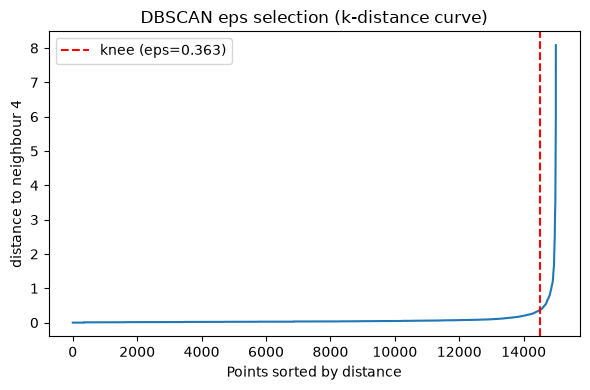

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/uber_pickups_dbscan_k_distance.png')

In [8]:
from sc4020.generate_figures import plot_k_distance, show_and_save

min_samples = tuning.min_samples_from_dimension(ds.data.shape[1])
curve = tuning.k_distance_curve(ds.data, min_samples)
knee_index, eps_at_knee = tuning.find_knee(curve)
fig = plot_k_distance(curve, knee_index, eps_at_knee, min_samples)
show_and_save(fig, TOPIC, f"{DATASET_NAME}_dbscan_k_distance")

In [9]:
selections["DBSCAN"] = run.select_method(ds, "DBSCAN", max_clusters=MAX_CLUSTERS)
results["DBSCAN"] = run.fit_method(ds, "DBSCAN", selections["DBSCAN"])
print(f"chosen: {run.format_params(selections['DBSCAN'].params)}, rule satisfied: {selections['DBSCAN'].valid}")
pd.DataFrame(selections["DBSCAN"].tried).round(3)

chosen: eps=2.81, min_samples=16, rule satisfied: True


,eps,min_samples,eps_factor,n_clusters,noise_fraction,largest_cluster_share,silhouette,passes
0,0.164,3,0.50,149,0.055,0.801,-0.281,True
1,0.245,3,0.75,104,0.034,0.803,-0.259,True
2,0.327,3,1.00,69,0.024,0.813,-0.092,True
3,0.409,3,1.25,62,0.018,0.814,-0.045,True
4,0.491,3,1.50,47,0.014,0.924,0.019,True
5,0.654,3,2.00,35,0.011,0.949,0.041,True
6,0.981,3,3.00,17,0.006,0.959,0.159,True
7,1.308,3,4.00,8,0.004,0.973,0.326,True
8,0.182,4,0.50,99,0.059,0.802,-0.175,True
9,0.272,4,0.75,64,0.037,0.806,-0.165,True


## 5. Clustering with HDBSCAN

In [10]:
selections["HDBSCAN"] = run.select_method(ds, "HDBSCAN", max_clusters=MAX_CLUSTERS)
results["HDBSCAN"] = run.fit_method(ds, "HDBSCAN", selections["HDBSCAN"])
print(f"chosen: {run.format_params(selections['HDBSCAN'].params)}, rule satisfied: {selections['HDBSCAN'].valid}")
pd.DataFrame(selections["HDBSCAN"].tried).round(3)

chosen: min_cluster_size=200, min_samples=None, rule satisfied: True


,min_cluster_size,min_samples,n_clusters,noise_fraction,largest_cluster_share,silhouette,passes
0,5,NaN,878,0.325,0.005,0.538,True
1,5,5.0,878,0.325,0.005,0.538,True
2,5,10.0,399,0.478,0.007,0.589,True
3,10,NaN,310,0.461,0.021,0.547,True
4,10,5.0,435,0.313,0.011,0.467,True
5,10,10.0,310,0.461,0.021,0.547,True
6,15,NaN,29,0.097,0.799,-0.026,True
7,15,5.0,288,0.341,0.013,0.437,True
8,15,10.0,41,0.090,0.800,-0.055,True
9,20,NaN,22,0.096,0.805,0.042,True


## 6. Clustering with GMM

The number of components and the covariance type with the lowest BIC (the number of components is the
number of classes on labelled data).

In [11]:
selections["GMM"] = run.select_method(ds, "GMM", k_range=k_range)
results["GMM"] = run.fit_method(ds, "GMM", selections["GMM"])
gmm_tried = pd.DataFrame(selections["GMM"].tried).rename(columns={"score": "minus_bic"})
print(f"chosen: {run.format_params(selections['GMM'].params)}, label-free: {run.format_params(selections['GMM'].label_free)}")
gmm_tried.pivot(index="n_components", columns="covariance_type", values="minus_bic").round(1)

chosen: n_components=9, covariance_type=full, label-free: n_components=9, covariance_type=full


covariance_type,diag,full,spherical,tied
n_components,,,,
2,-142329.6,-135724.6,-146157.8,-148375.5
3,-136854.3,-133646.4,-138846.5,-148374.8
4,-133025.6,-130583.7,-136402.7,-137404.4
5,-131950.2,-129743.0,-133940.2,-137516.1
6,-129927.1,-129003.9,-131454.7,-136540.2
7,-129896.2,-128913.5,-130580.4,-135265.2
8,-128450.4,-126648.2,-130015.4,-135887.5
9,-127363.0,-126225.8,-128462.3,-134397.9
10,-126722.4,-128132.1,-127274.2,-135439.8


## 7. Clustering with Spectral

Spectral clustering at the K-Means k: an RBF affinity on Wine, a 10-nearest-neighbour graph elsewhere
(`run.SPECTRAL_AFFINITY_BY_DATASET`). A dense RBF affinity needs memory quadratic in the number of
points, so it is skipped on large data; the nearest-neighbour graph is sparse and runs at any size.

In [12]:
if run.is_too_large(ds, "Spectral"):
    print(f"skipping Spectral: {len(ds.data):,} points is above {run.MAX_POINTS_FOR_DENSE_SPECTRAL:,}")
else:
    selections["Spectral"] = run.select_method(ds, "Spectral", selections)
    results["Spectral"] = run.fit_method(ds, "Spectral", selections["Spectral"])
    print(f"Spectral: {run.format_params(selections['Spectral'].params)}")

Spectral: n_clusters=5, affinity=nearest_neighbors


## 8. Metrics

Internal scores (silhouette, Davies-Bouldin, DBCV) need no labels; ARI and NMI compare with the classes
when there are any. Noise points are left out of the internal scores. The null columns refit each
method at its setting on a copy with every column shuffled: a silhouette near the null one means the
clusters are no stronger than on data without structure.

In [13]:
table = run.score_methods(ds, selections, results)
run.save_dataset_run(DATASET_NAME, table, run.tried_settings(ds, selections))
columns = [
    "method",
    "params",
    "n_clusters",
    "noise_fraction",
    "largest_cluster_share",
    "silhouette",
    "davies_bouldin",
    "dbcv",
    "ari",
    "nmi",
    "fit_seconds",
    "null_silhouette",
]
table[[column for column in columns if column in table]].round(3)

,method,params,n_clusters,noise_fraction,largest_cluster_share,silhouette,davies_bouldin,dbcv,fit_seconds,null_silhouette
0,K-Means (random init),n_clusters=5,5,0.000,0.445,0.481,0.699,-0.786,0.025,0.396
1,K-Means,n_clusters=5,5,0.000,0.445,0.481,0.699,-0.786,0.893,0.338
2,DBSCAN,"eps=2.81, min_samples=16",2,0.002,0.977,0.757,0.186,0.208,0.903,NaN
3,HDBSCAN,"min_cluster_size=200, min_samples=None",3,0.046,0.915,0.638,0.267,0.404,0.975,0.660
4,GMM,"n_components=9, covariance_type=full",9,0.000,0.256,0.359,1.624,-0.648,0.804,0.331
5,Spectral,"n_clusters=5, affinity=nearest_neighbors",5,0.000,0.353,0.157,1.389,-0.917,1.070,0.308


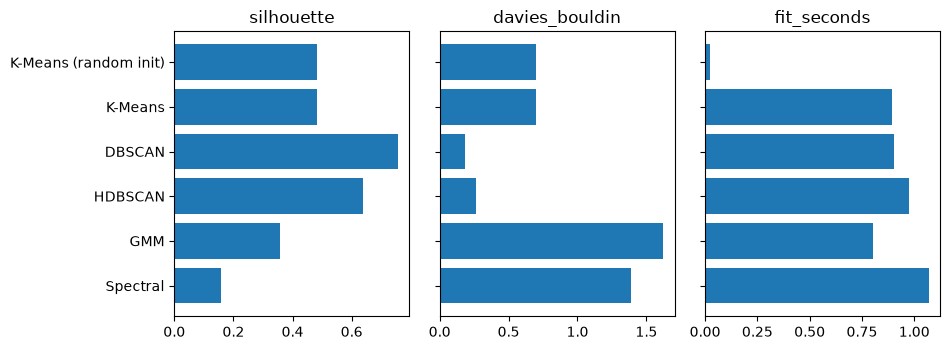

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/uber_pickups_metrics.png')

In [14]:
from sc4020.generate_figures import show_and_save

metric_names = [m for m in ("silhouette", "davies_bouldin", "ari", "fit_seconds") if m in table]
fig, axes = plt.subplots(1, len(metric_names), figsize=(3.2 * len(metric_names), 3.6), sharey=True)
for ax, metric in zip(axes, metric_names):
    ax.barh(table["method"], table[metric])
    ax.set_title(metric)
axes[0].invert_yaxis()
fig.tight_layout()
show_and_save(fig, TOPIC, f"{DATASET_NAME}_metrics")

## 9. Visualization

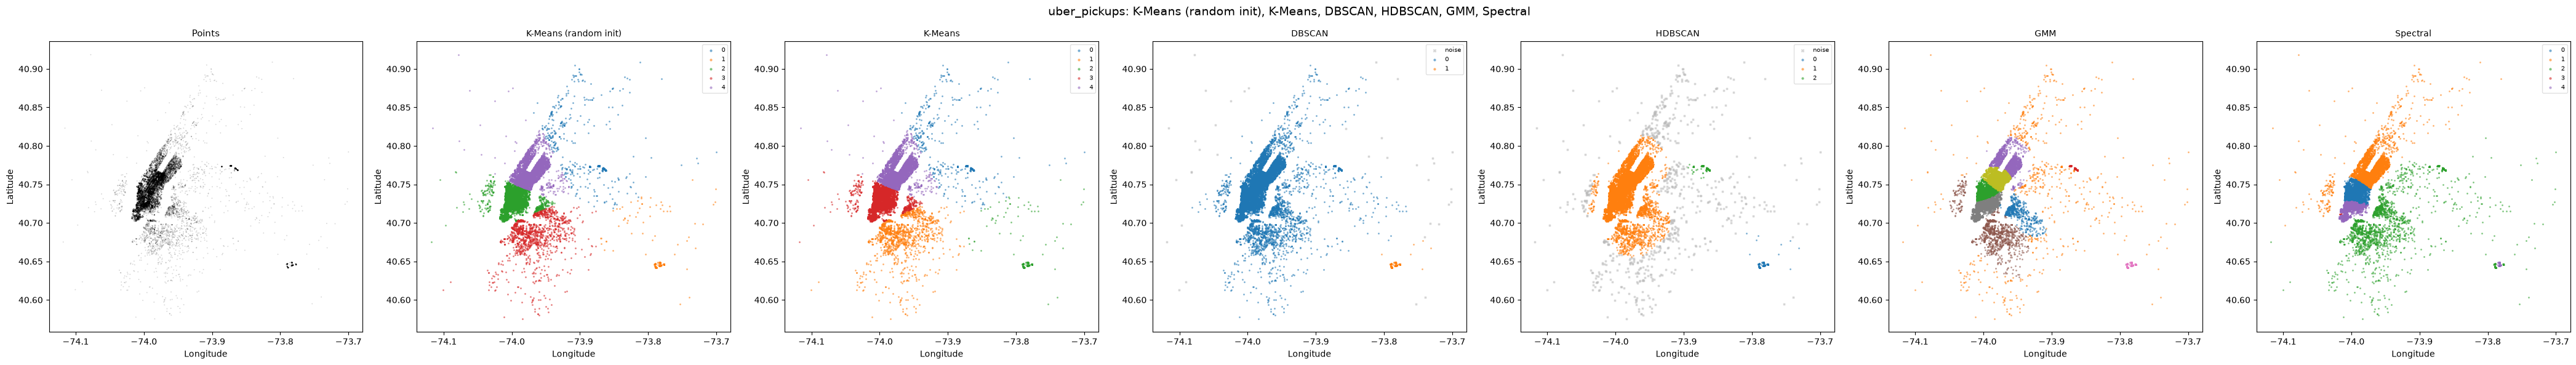

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/uber_pickups_clusters.png')

In [15]:
from sc4020.generate_figures import show_and_save

fig = run.plot_dataset(ds, results, table, title=f"{DATASET_NAME}: {', '.join(results)}")
show_and_save(fig, TOPIC, f"{DATASET_NAME}_clusters")